# Tugas Praktikum 6 · Clustering (Advance)

**Prima Surya Nusantara · 5054251036 · Data Mining RKA**

## 1. Impor dataset

Data berasal dari [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/) (Horst, Hill, dan Gorman, 2020). Notebook mencoba membaca CSV resmi melalui URL, dengan salinan lokal sebagai cadangan.

In [1]:
from pathlib import Path
from urllib.error import URLError

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import dendrogram
from sklearn.base import clone
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    rand_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

URL_DATA = (
    "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/"
    "main/inst/extdata/penguins.csv"
)
CSV_LOKAL = Path("penguins.csv")

try:
    data = pd.read_csv(URL_DATA)
    sumber_data = "URL resmi Palmer Penguins"
except (URLError, TimeoutError) as galat:
    if not CSV_LOKAL.is_file():
        raise FileNotFoundError(
            "URL tidak dapat diakses. Tempatkan penguins.csv di folder notebook."
        ) from galat
    data = pd.read_csv(CSV_LOKAL)
    sumber_data = "penguins.csv lokal (URL tidak dapat diakses)"

print(f"Sumber yang digunakan — {sumber_data}")
display(data.head())
print("Dimensi data", data.shape)
data.info()

Sumber yang digunakan — URL resmi Palmer Penguins


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


Dimensi data (344, 8)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


## 2. Eksplorasi dan pembersihan

Baris dibuang jika salah satu fitur pengukuran atau label `species` kosong. Nilai kosong pada `sex` di luar kriteria pembersihan karena kolom itu tidak digunakan untuk pemodelan maupun evaluasi.

In [2]:
fitur = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
]
label_pembanding = "species"
nilai_kosong = data.isna().sum().rename("Jumlah kosong")
data_bersih = data.dropna(subset=[*fitur, label_pembanding]).copy()
jumlah_spesies = data_bersih[label_pembanding].value_counts().sort_index()
statistik = data_bersih[fitur].describe()

display(nilai_kosong.to_frame())
print(f"Sebelum pembersihan {len(data)} baris")
print(f"Sesudah pembersihan {len(data_bersih)} baris")
display(jumlah_spesies.rename("Jumlah setelah pembersihan").to_frame())
display(statistik.round(2))

,Jumlah kosong
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


Sebelum pembersihan 344 baris
Sesudah pembersihan 342 baris


,Jumlah setelah pembersihan
species,
Adelie,151
Chinstrap,68
Gentoo,123


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
std,5.46,1.97,14.06,801.95
min,32.10,13.10,172.00,2700.00
25%,39.22,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


Massa tubuh (gram) memiliki rentang numerik yang jauh lebih lebar daripada panjang dan kedalaman paruh atau panjang sirip (milimeter). Scatter plot menampilkan dua pengukuran dalam satuan asli.

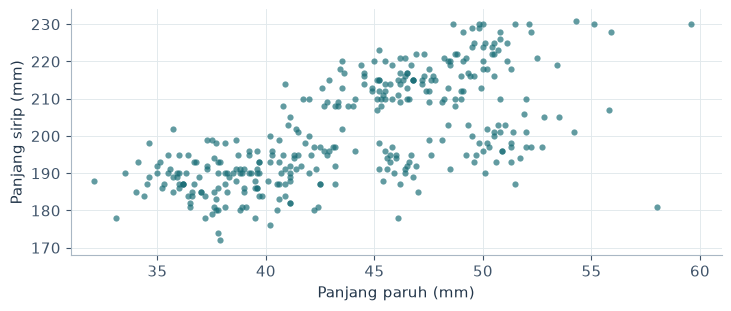

In [3]:
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelcolor": "#23364a",
    "axes.edgecolor": "#a9b7c4",
    "axes.titleweight": "bold",
    "axes.titlecolor": "#18344b",
    "xtick.color": "#40546a",
    "ytick.color": "#40546a",
    "grid.color": "#e1e8ec",
    "font.size": 11,
})

def atur_sumbu(ax):
    ax.set(
        xlabel="Panjang paruh (mm)",
        ylabel="Panjang sirip (mm)",
        xlim=(31, 61),
        ylim=(168, 234),
    )
    ax.set_axisbelow(True)
    ax.grid(linewidth=0.65)

fig_eda, ax = plt.subplots(figsize=(7.2, 3.0), layout="constrained")
ax.scatter(
    data_bersih["bill_length_mm"], data_bersih["flipper_length_mm"],
    s=20, color="#176c75", alpha=0.68, linewidths=0,
)
atur_sumbu(ax)
plt.show()

## 3. Standardisasi data

`StandardScaler` mengubah tiap fitur menjadi z-score dengan rata-rata 0 dan simpangan baku populasi 1. Matriks `X_std` menjadi input seluruh model. `y` menyimpan spesies untuk evaluasi eksternal. Matriks lengkap tersedia sebagai `data_standar`. Untuk menyimpannya sebagai CSV lokal, jalankan `data_standar.to_csv("penguins_standar.csv")`.

In [4]:
X = data_bersih[fitur]
y = data_bersih[label_pembanding]

scaler = StandardScaler()
X_std = scaler.fit_transform(X)
data_standar = pd.DataFrame(
    X_std,
    index=X.index,
    columns=[f"z_{kolom}" for kolom in fitur],
)
data_standar.index.name = "indeks_baris_asli"

print("Dimensi data standar", data_standar.shape)
display(data_standar.head().round(3))
display(pd.DataFrame({
    "Rata-rata": data_standar.mean(),
    "Simpangan baku (ddof=0)": data_standar.std(ddof=0),
}).round(6))

Dimensi data standar (342, 4)


,z_bill_length_mm,z_bill_depth_mm,z_flipper_length_mm,z_body_mass_g
indeks_baris_asli,,,,
0,-0.884,0.785,-1.418,-0.564
1,-0.811,0.126,-1.062,-0.502
2,-0.664,0.430,-0.421,-1.189
4,-1.325,1.090,-0.564,-0.939
5,-0.848,1.749,-0.777,-0.689


,Rata-rata,Simpangan baku (ddof=0)
z_bill_length_mm,0.0,1.0
z_bill_depth_mm,0.0,1.0
z_flipper_length_mm,-0.0,1.0
z_body_mass_g,0.0,1.0


## 4. Penerapan algoritma

| Algoritma | Konfigurasi |
| --- | --- |
| Agglomerative | 3 kluster, linkage Ward (jarak Euclidean) |
| DBSCAN | epsilon 0,50 dan MinPts 5 untuk perbandingan utama |
| Gaussian Mixture Model (GMM) | 3 komponen, kovarians penuh, 10 inisialisasi |
| Spectral | 3 kluster, afinitas RBF dengan gamma 1, pelabelan K-means dengan 10 inisialisasi |

GMM dan Spectral memakai seed 42. Nilai epsilon tambahan digunakan untuk memeriksa sensitivitas DBSCAN.

In [5]:
SEED_MODEL = 42
EPS_UTAMA = 0.50
MIN_PTS = 5
model = {
    "Agglomerative": AgglomerativeClustering(
        n_clusters=3, linkage="ward", compute_distances=True
    ),
    "DBSCAN": DBSCAN(eps=EPS_UTAMA, min_samples=MIN_PTS),
    "GMM": GaussianMixture(
        n_components=3, covariance_type="full", n_init=10, random_state=SEED_MODEL
    ),
    "Spectral": SpectralClustering(
        n_clusters=3, affinity="rbf", gamma=1.0, assign_labels="kmeans",
        n_init=10, random_state=SEED_MODEL,
    ),
}
label_cluster = {
    nama: estimator.fit_predict(X_std)
    for nama, estimator in model.items()
}

### Dendrogram Agglomerative

Ward menggabungkan pasangan kluster yang menimbulkan kenaikan terkecil pada jumlah kuadrat dalam kluster. Dendrogram menampilkan 24 cabang terminal terakhir. Angka dalam tanda kurung menunjukkan jumlah observasi di cabang yang diringkas.

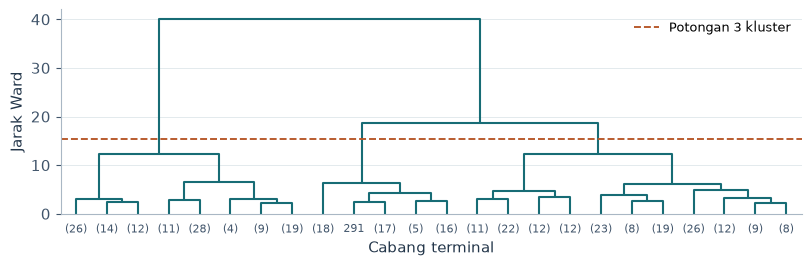

In [6]:
hierarki = model["Agglomerative"]
ukuran = np.zeros(len(hierarki.children_), dtype=int)
for i, (kiri, kanan) in enumerate(hierarki.children_):
    ukuran[i] = sum(
        1 if cabang < len(X) else ukuran[cabang - len(X)]
        for cabang in (kiri, kanan)
    )
matriks_linkage = np.column_stack(
    (hierarki.children_, hierarki.distances_, ukuran)
).astype(float)
batas_potong = np.mean(hierarki.distances_[-3:-1])

fig_ward, ax = plt.subplots(figsize=(8.0, 2.55), layout="constrained")
dendrogram(
    matriks_linkage, truncate_mode="lastp", p=24, leaf_rotation=0,
    leaf_font_size=8, color_threshold=0, above_threshold_color="#176c75", ax=ax,
)
ax.axhline(
    batas_potong, color="#b65627", linestyle="--", linewidth=1.35,
    label="Potongan 3 kluster",
)
ax.set(xlabel="Cabang terminal", ylabel="Jarak Ward")
ax.set_axisbelow(True)
ax.grid(axis="y", linewidth=0.65)
ax.legend(frameon=False, loc="upper right", fontsize=9)
plt.show()

### Sensitivitas DBSCAN terhadap epsilon

MinPts tetap 5. Noise berlabel −1 dan dihitung terpisah dari jumlah kluster.

In [7]:
def ringkas_label(labels):
    nilai = np.unique(labels)
    return {
        "Kluster": int(np.count_nonzero(nilai != -1)),
        "Noise": int(np.count_nonzero(labels == -1)),
    }

uji_eps = []
for eps in (EPS_UTAMA, 0.30, 0.40, 0.60, 0.70, 0.80):
    labels = (
        label_cluster["DBSCAN"]
        if eps == EPS_UTAMA
        else DBSCAN(eps=eps, min_samples=MIN_PTS).fit_predict(X_std)
    )
    uji_eps.append({"Epsilon": eps, **ringkas_label(labels)})

tabel_eps = pd.DataFrame(uji_eps).sort_values("Epsilon", ignore_index=True)
display(tabel_eps.set_index("Epsilon"))

,Kluster,Noise
Epsilon,,
0.3,4,317
0.4,10,171
0.5,4,69
0.6,2,33
0.7,2,16
0.8,2,5


### Scatter plot tiap algoritma

Keempat model memanfaatkan semua fitur terstandardisasi. Scatter plot memproyeksikan hasil ke dua pengukuran asli. Nomor kluster berlaku di panel masing-masing.

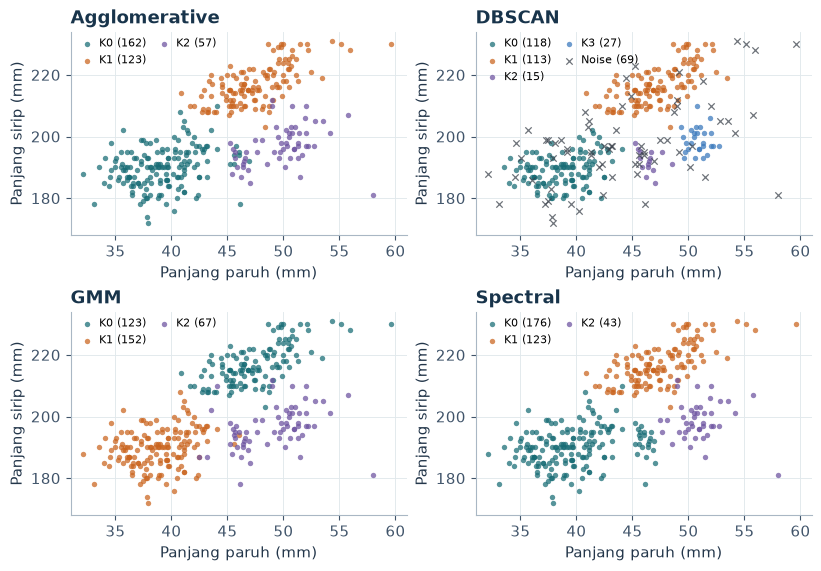

In [8]:
warna_kluster = ["#176c75", "#ca641e", "#6c52a0", "#3878bc"]
fig_cluster, axes = plt.subplots(2, 2, figsize=(8.1, 5.6), layout="constrained")
for ax, (nama, labels) in zip(axes.flat, label_cluster.items()):
    for label in sorted(np.unique(labels), key=lambda nomor: (nomor == -1, nomor)):
        titik = X.iloc[np.flatnonzero(labels == label)]
        noise = label == -1
        ax.scatter(
            titik["bill_length_mm"],
            titik["flipper_length_mm"],
            color="#383f49" if noise else warna_kluster[label % len(warna_kluster)],
            marker="x" if noise else "o",
            s=21 if noise else 15,
            alpha=0.73,
            linewidths=0.9 if noise else 0,
            label=f"Noise ({len(titik)})" if noise else f"K{label} ({len(titik)})",
        )
    atur_sumbu(ax)
    ax.set_title(nama, loc="left")
    ax.legend(
        frameon=False, fontsize=7.6, loc="upper left", ncol=2,
        columnspacing=0.7, handletextpad=0.15, borderaxespad=0.15,
    )
plt.show()

## 5. Evaluasi hasil clustering

- **Silhouette** mengukur kekompakan dan keterpisahan kluster di ruang empat fitur standar. Titik noise DBSCAN dikeluarkan hanya dari perhitungan ini. Silhouette ditampilkan sebagai N/A jika kluster yang tersisa kurang dari dua atau setiap titik memiliki kluster sendiri.
- **Rand Index** mengukur kesepakatan pasangan observasi dengan pengelompokan berdasarkan spesies. **NMI** mengukur informasi yang dibagi kedua pengelompokan. Keduanya dihitung pada seluruh observasi dan memasukkan label noise DBSCAN sebagai kategori tersendiri.
- **Kestabilan** diukur dengan Adjusted Rand Index (ARI) dari pengelompokan pada subset terhadap hasil data penuh untuk baris yang sama. Nilai 1 menunjukkan partisi identik. Nilai 0 menunjukkan tingkat kesepakatan yang diharapkan secara acak. ARI tidak dipengaruhi pergantian nomor kluster.

In [9]:
baris_evaluasi = []
for nama, labels in label_cluster.items():
    ringkasan = ringkas_label(labels)
    mask = labels != -1
    banyak_label = ringkasan["Kluster"]
    silhouette = (
        silhouette_score(X_std[mask], labels[mask])
        if 2 <= banyak_label < mask.sum()
        else np.nan
    )
    baris_evaluasi.append({
        "Algoritma": nama,
        **ringkasan,
        "Silhouette": silhouette,
        "Rand Index": rand_score(y, labels),
        "NMI": normalized_mutual_info_score(y, labels),
    })

evaluasi = pd.DataFrame(baris_evaluasi).set_index("Algoritma")
print(f"Titik DBSCAN yang dikeluarkan dari silhouette {evaluasi.loc['DBSCAN', 'Noise']}")

Titik DBSCAN yang dikeluarkan dari silhouette 69


### Uji kestabilan

Tiga subset acak diambil tanpa pengembalian, masing-masing berisi 90% data bersih (dibulatkan ke baris terdekat). Keempat model memakai subset yang sama pada tiap ulangan. StandardScaler dan model di-fit ulang pada setiap subset dengan konfigurasi tetap. Untuk DBSCAN, label noise ikut dibandingkan dalam ARI.

In [10]:
seed_subset = (11, 22, 33)
n_subset = round(0.90 * len(X))
ari = pd.DataFrame(index=evaluasi.index)
for ulangan, seed in enumerate(seed_subset, start=1):
    rng = np.random.default_rng(seed)
    posisi = np.sort(rng.choice(len(X), n_subset, replace=False))
    X_subset = StandardScaler().fit_transform(X.iloc[posisi])
    ari[f"ARI {ulangan}"] = {
        nama: adjusted_rand_score(
            label_cluster[nama][posisi], clone(estimator).fit_predict(X_subset)
        )
        for nama, estimator in model.items()
    }

ari["Rerata ARI"] = ari.mean(axis=1)
perbandingan = evaluasi.join(ari)

print(f"Baris per subset {n_subset} dari {len(X)}")
tampilan = perbandingan.copy()
for kolom in tampilan.columns[2:]:
    tampilan[kolom] = tampilan[kolom].map(
        lambda nilai: f"{nilai:.3f}" if pd.notna(nilai) else "N/A"
    )
display(tampilan)

Baris per subset 308 dari 342


,Kluster,Noise,Silhouette,Rand Index,NMI,ARI 1,ARI 2,ARI 3,Rerata ARI
Algoritma,,,,,,,,,
Agglomerative,3,0,0.454,0.961,0.901,0.939,0.939,0.965,0.947
DBSCAN,4,69,0.424,0.853,0.663,0.805,0.939,0.821,0.855
GMM,3,0,0.455,0.982,0.935,1.000,1.000,0.991,0.997
Spectral,3,0,0.462,0.917,0.831,1.000,1.000,1.000,1.000


### Kesesuaian kluster dengan spesies

Tabel silang memperlihatkan spesies mana yang terkumpul atau tercampur di setiap kluster.

In [11]:
tabel_silang = {
    nama: pd.crosstab(y, pd.Series(labels, index=y.index, name="Kluster"))
    for nama, labels in label_cluster.items()
}
for nama, tabel in tabel_silang.items():
    display(Markdown(f"**{nama}**"))
    display(tabel.rename(columns={-1: "Noise"}))

**Agglomerative**

Kluster,0,1,2
species,,,
Adelie,151,0,0
Chinstrap,11,0,57
Gentoo,0,123,0


**DBSCAN**

Kluster,Noise,0,1,2,3
species,,,,,
Adelie,36,115,0,0,0
Chinstrap,23,3,0,15,27
Gentoo,10,0,113,0,0


**GMM**

Kluster,0,1,2
species,,,
Adelie,0,149,2
Chinstrap,0,3,65
Gentoo,123,0,0


**Spectral**

Kluster,0,1,2
species,,,
Adelie,151,0,0
Chinstrap,25,0,43
Gentoo,0,123,0


## 6. Kesimpulan

Karena salah satu tujuan analisis adalah melihat apakah pengelompokan morfologi mendekati spesies, NMI dan Rand Index digunakan untuk menilai kesesuaian tersebut. Silhouette dan ARI menjawab pertanyaan berbeda tentang bentuk serta kestabilan partisi.

In [12]:
pilihan = perbandingan["NMI"].idxmax()
pemenang_silhouette = perbandingan["Silhouette"].idxmax()
pemenang_ari = perbandingan["Rerata ARI"].idxmax()
hasil = perbandingan.loc[pilihan]
dbscan = perbandingan.loc["DBSCAN"]

display(Markdown(
    f"**{pilihan} paling sesuai untuk mendekati pengelompokan spesies** "
    f"pada dataset ini, dengan NMI **{hasil['NMI']:.3f}**, "
    f"Rand Index **{hasil['Rand Index']:.3f}**, dan rerata ARI "
    f"**{hasil['Rerata ARI']:.3f}**. "
    f"Silhouette tertinggi diperoleh **{pemenang_silhouette}** "
    f"({perbandingan.loc[pemenang_silhouette, 'Silhouette']:.3f}), "
    f"sedangkan rerata ARI tertinggi diperoleh **{pemenang_ari}** "
    f"({perbandingan.loc[pemenang_ari, 'Rerata ARI']:.3f}). "
    f"DBSCAN dengan epsilon {EPS_UTAMA:.2f} menghasilkan "
    f"{int(dbscan['Kluster'])} kluster dan {int(dbscan['Noise'])} titik noise. "
    f"Silhouette DBSCAN berlaku pada {len(X) - int(dbscan['Noise'])} titik "
    "non-noise, sehingga cakupannya berbeda dari ketiga metode lain."
))

**GMM paling sesuai untuk mendekati pengelompokan spesies** pada dataset ini, dengan NMI **0.935**, Rand Index **0.982**, dan rerata ARI **0.997**. Silhouette tertinggi diperoleh **Spectral** (0.462), sedangkan rerata ARI tertinggi diperoleh **Spectral** (1.000). DBSCAN dengan epsilon 0.50 menghasilkan 4 kluster dan 69 titik noise. Silhouette DBSCAN berlaku pada 273 titik non-noise, sehingga cakupannya berbeda dari ketiga metode lain.